# Symmetrien: was sich wiederholt, muss man nur einmal rechnen

Wo sich ein System unter einer Operation nicht ändert, liefert diese Symmetrie die richtigen Koordinaten, bevor man irgendetwas misst. Das Notebook zeigt das an sieben Beispielen: Fourier-Moden auf einem Ring, Blöcke im Hilbertraum einer Spinkette, Clifford-Schaltkreise, die ein Laptop für tausend Qubits simuliert, die Berry-Phase auf der Bloch-Kugel, die verborgene Symmetrie der Kepler-Bahn mit dem Perihel des Merkur, die kosmische Varianz im Planck-Spektrum und der Alcock-Paczynski-Test mit den BAO-Daten von DESI. Der Code steht in [`code/symmetries/`](https://github.com/deltorobarba/science/tree/main/code/symmetries) (`symmetry.py` für Ring, Spinkette und Berry-Phase, `stabilizer.py` für die Clifford-Schaltkreise, `orbits.py` für die Kepler-Bahn, `cosmo.py` für Planck und DESI); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Wo sich etwas wiederholt, muss man es nur einmal beschreiben. Das ist der Gegenpol zu `principal_axes`: Dort findet man die wichtigen Richtungen aus den Daten und lässt den Rest weg; hier liefert eine Symmetrie sie, bevor man misst. Zusammen mit `approximation`, das die führenden Terme behält, sind das drei Arten, Kompliziertes einfach zu machen.

- **Schritt 1, Mathematik:** Translationssymmetrie macht die Fourier-Moden zu den Hauptachsen jeder Matrix, die nur vom Abstand abhängt. Das erklärt nachträglich, warum das LIGO-Rauschen in `principal_axes` in Frequenzen zerfiel.
- **Schritt 2, Quantenphysik:** Eine Erhaltungsgröße zerlegt den Hilbertraum in unabhängige Blöcke; wer sie übersieht, zieht falsche Schlüsse über Chaos.
- **Schritt 3, Quanteninformation:** Die Symmetrien der Pauli-Gruppe, die Clifford-Gatter, machen manche Quantenschaltkreise klassisch simulierbar: 2n² Bit statt 2ⁿ Amplituden.
- **Schritt 4, Geometrie:** Der Zustandsraum eines Qubits ist eine Kugel, und eine Phase merkt sich deren Geometrie, den Raumwinkel.
- **Schritt 5, Himmelsmechanik:** Die verborgene Symmetrie der Kepler-Bahn hält die Bahnen geschlossen; wo sie bricht, misst man die allgemeine Relativitätstheorie.
- **Schritte 6 und 7, Kosmologie:** Weil das Universum in allen Richtungen gleich aussieht, ist die Zahl der unabhängigen Moden am Himmel begrenzt (kosmische Varianz), und die Form der BAO-Struktur misst die Materiedichte ohne Lineal.

Die gemeinsame Lehre: Eine Symmetrie liefert die richtigen Koordinaten umsonst, und wo eine erwartete Symmetrie bricht, steckt oft eine Entdeckung.

**Einführung: Symmetrie liefert die Achsen umsonst**

Ein kleines Beispiel zuerst, dasselbe wie in der Einführung von `principal_axes`: zwei Messgeräte mit der Kovarianz

$$C = \begin{pmatrix} a & b \\ b & a \end{pmatrix}.$$

Dort wurden die Hauptachsen ausgerechnet. Hier genügt ein Blick: Vertauscht man die beiden Geräte, bleibt $C$ gleich. Die Vertauschung $S = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$ kommutiert also mit $C$, $SC = CS$, und hat die Eigenvektoren $(1, 1)/\sqrt2$ mit Eigenwert $+1$ und $(1, -1)/\sqrt2$ mit Eigenwert $-1$. Weil diese beiden Eigenwerte verschieden sind, muss $C$ dieselben Eigenvektoren haben, für jedes $a$ und jedes $b$; nur die Eigenwerte $a + b$ und $a - b$ hängen von den Zahlen ab. Zum Nachrechnen: $C\,(1, 1)^T = (a + b)\,(1, 1)^T$.

Allgemein ist eine Symmetrie eine Operation $g$, die das System nicht ändert; alle zusammen bilden eine Gruppe $G$. Kommutiert eine Matrix $H$ mit allen $g$, zerfällt sie in Blöcke, einen für jede Darstellung der Gruppe (Lemma von Schur), und in jedem Block bleibt wenig zu rechnen. Drei Folgen ziehen sich durch das Notebook:

- **Diagonalisieren ohne Rechnen:** Für die Verschiebung um eine Stelle sind die Fourier-Moden die gemeinsamen Eigenvektoren, für Drehungen der Kugel die Kugelflächenfunktionen $Y_{\ell m}$.
- **Erhaltungsgrößen:** Zu jeder kontinuierlichen Symmetrie gehört eine Erhaltungsgröße (Noether): zur Zeitverschiebung die Energie, zur Drehung der Drehimpuls. Die Erhaltungsgröße nummeriert die Blöcke.
- **Gebrochene Symmetrie als Messung:** Gilt eine erwartete Symmetrie nicht exakt, ist die Abweichung selbst das Signal.

| Gebiet (Schritt) | Symmetrie | was sie vereinfacht | Ergebnis im Lauf |
|---|---|---|---|
| Mathematik (1) | Verschiebung auf einem Ring | Eigenvektoren = Fourier-Moden | Eigenwerte auf 10⁻¹⁵ genau, über tausendmal schneller |
| Quantenphysik (2) | Erhaltung der Magnetisierung | Hilbertraum in 13 Blöcke | 25-mal schneller; ohne Blöcke falsche Niveaustatistik |
| Quanteninformation (3) | Clifford-Gruppe | 2n² Bit statt 2ⁿ Amplituden | 1000 Qubits auf dem Laptop |
| Geometrie (4) | Drehung der Bloch-Kugel | Phase = halber Raumwinkel | auf 0.02 rad genau |
| Himmelsmechanik (5) | verborgene Symmetrie des 1/r²-Gesetzes | geschlossene Bahnen | Merkur: 42.98″ pro Jahrhundert |
| Kosmologie (6, 7) | Isotropie | 2ℓ + 1 Moden je ℓ, runde BAO | kosmische Varianz; Ω_m = 0.299 ± 0.017 |

In [1]:
import sys
import urllib.request
from pathlib import Path
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "symmetries"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["symmetry.py", "stabilizer.py", "orbits.py", "cosmo.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/symmetries/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import symmetry, stabilizer, orbits, cosmo
DATA = Path.cwd() / "data" / "symmetries"              # Cache für Planck und DESI

**1. Translationssymmetrie: warum die Hauptachsen Sinuswellen sind**

Ein Ring aus 200 Gliedern, jedes mit seinen Nachbarn bis zum Abstand 4 durch Federn verbunden, mit willkürlich gewählten Stärken (1, 0.45, −0.2 und 0.07). Die Kopplungsmatrix hängt nur vom Abstand zweier Glieder ab; dreht man den Ring um ein Glied weiter, bleibt sie gleich. Deshalb müssen ihre Eigenvektoren die der Verschiebung sein, die Fourier-Moden, und ihre Eigenwerte die Fourier-Transformierte einer Zeile (`symmetry.plot_ring`). Verglichen wird das mit der vollen Zerlegung der Matrix.

**Begriffe**
- **Zirkulante Matrix:** Jede Zeile ist die vorige, um eine Stelle verschoben; sie beschreibt alles, was auf einem Ring nur vom Abstand abhängt.
- **Fourier-Mode:** $e^{iqj}$ auf Glied $j$; die Verschiebung multipliziert sie nur mit $e^{iq}$.
- **Rechenaufwand:** Die volle Zerlegung wächst wie $N^3$, die schnelle Fourier-Transformation wie $N \log N$.

Links die ersten Eigenvektoren aus der vollen Zerlegung: eine Konstante, dann Sinuswellen mit einer, zwei und fünf Perioden um den Ring (je zwei Eigenvektoren teilen sich eine Frequenz, Kosinus und Sinus). Rechts liegen die Eigenwerte auf der Fourier-Transformierten der ersten Zeile, auf 3·10⁻¹⁵ genau, und das für beliebige Federstärken: Nicht die Zahlen, sondern die Symmetrie bestimmt die Achsen. Bei 2000 Gliedern braucht die volle Zerlegung rund 0.3 s, die Fourier-Transformation einige Hundertstel Millisekunden, mehrere tausendmal weniger. Dasselbe erklärt das LIGO-Rauschen in `principal_axes`: Stationäres Rauschen ändert sich nicht, wenn man es in der Zeit verschiebt, deshalb waren seine Hauptachsen Frequenzen und seine Eigenwerte das Leistungsspektrum.

Ring aus 200 Gliedern, Kopplungen (1.0, 0.45, -0.2, 0.07) zu den Nachbarn im Abstand 1 bis 4
  Eigenwerte aus der vollen Zerlegung und aus der Fourier-Transformation der ersten Zeile: größte Abweichung 2.7e-15


  Rechenzeit für 2000 Glieder: volle Zerlegung 0.32 s, Fourier 0.05 ms (etwa 6021-mal schneller)


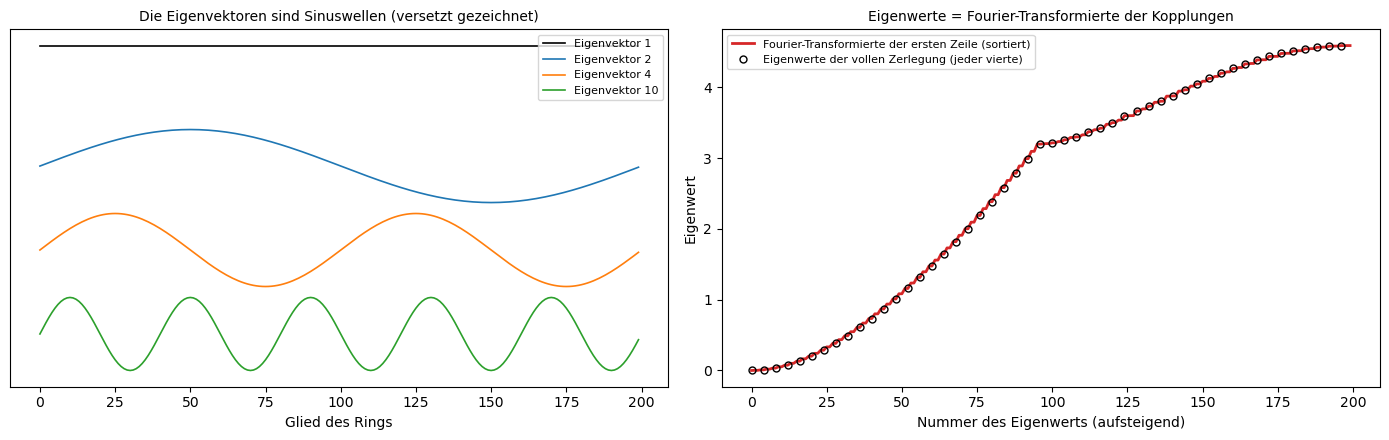

In [2]:
N, COUPLINGS = 200, (1.0, 0.45, -0.2, 0.07)        # Glieder, Federstärken zu den Nachbarn im Abstand 1 bis 4
symmetry.plot_ring(N, COUPLINGS, N_time=2000)

**2. Erhaltungsgrößen: ein Hilbertraum in Blöcken**

Eine Kette aus 12 Spins, jeder mit seinen Nachbarn gekoppelt (XXZ-Modell) und einem zufälligen Feld in z-Richtung ausgesetzt, hat 4096 Zustände. Das Feld zerstört fast jede Symmetrie, eine bleibt: Die Gesamtmagnetisierung, die Zahl der Spins nach oben, ändert sich nie, denn die Kopplung tauscht nur benachbarte Spins, die verschieden stehen. Sortiert man die Zustände danach, zerfällt der Hamilton-Operator in 13 Blöcke (`symmetry.plot_sectors`). Gemessen werden die Rechenzeit und die Statistik der Abstände zwischen benachbarten Energien, an der man Chaos erkennt.

**Begriffe**
- **XXZ-Kette:** $H = \sum_i (S^x_i S^x_{i+1} + S^y_i S^y_{i+1} + \Delta\, S^z_i S^z_{i+1}) + \sum_i h_i S^z_i$, hier mit $\Delta = 1$ und Feldern $h_i$ zufällig zwischen −1 und 1.
- **Verhältnis r:** der kleinere geteilt durch den größeren von zwei benachbarten Energieabständen. Unabhängige Energien (Poisson) geben im Mittel 0.386; in chaotischen Systemen stoßen sich die Niveaus ab, und es kommt 0.531 heraus wie bei Zufallsmatrizen (GOE).
- **Block:** alle Zustände mit demselben Wert der Erhaltungsgröße; zwischen verschiedenen Blöcken koppelt der Hamilton-Operator nie.

Links die Matrix für 8 Spins: in der gezählten Basis verstreut, nach Magnetisierung sortiert blockdiagonal. Für 12 Spins sind die Blöcke 1, 12, 66, 220, 495, 792 und 924 Zustände groß (und symmetrisch dazu); alle Eigenwerte kosten zusammen rund 3.4 s, Block für Block 0.16 s, mit genau denselben Eigenwerten. Rechts die Falle: Alle Blöcke gemischt geben ⟨r⟩ = 0.391, fast Poisson, als wären die Energien unabhängig. Ein einzelner Block gibt 0.537, nah an der Zufallsmatrix: Die Kette ist chaotisch. Energien aus verschiedenen Blöcken wissen nichts voneinander und dürfen sich beliebig nahe kommen; mischt man sie, verwischt man die Abstoßung innerhalb jedes Blocks. Wer die Symmetrie übersieht, hält ein chaotisches System für ein geordnetes.

XXZ-Kette mit 12 Spins: 4096 Zustände; Blöcke nach der Zahl der Spins oben: 1, 12, 66, 220, 495, 792, 924, 792, 495, 220, 66, 12, 1 (größter 924)
  Eigenwerte ganz 3.51 s, in Blöcken 0.15 s; dieselben Eigenwerte: True
  mittleres r: alle Blöcke gemischt 0.391, nur der Block mit 6 Spins oben 0.537 (Poisson, unabhängige Niveaus: 0.386; Zufallsmatrizen GOE, Niveauabstoßung: 0.531)


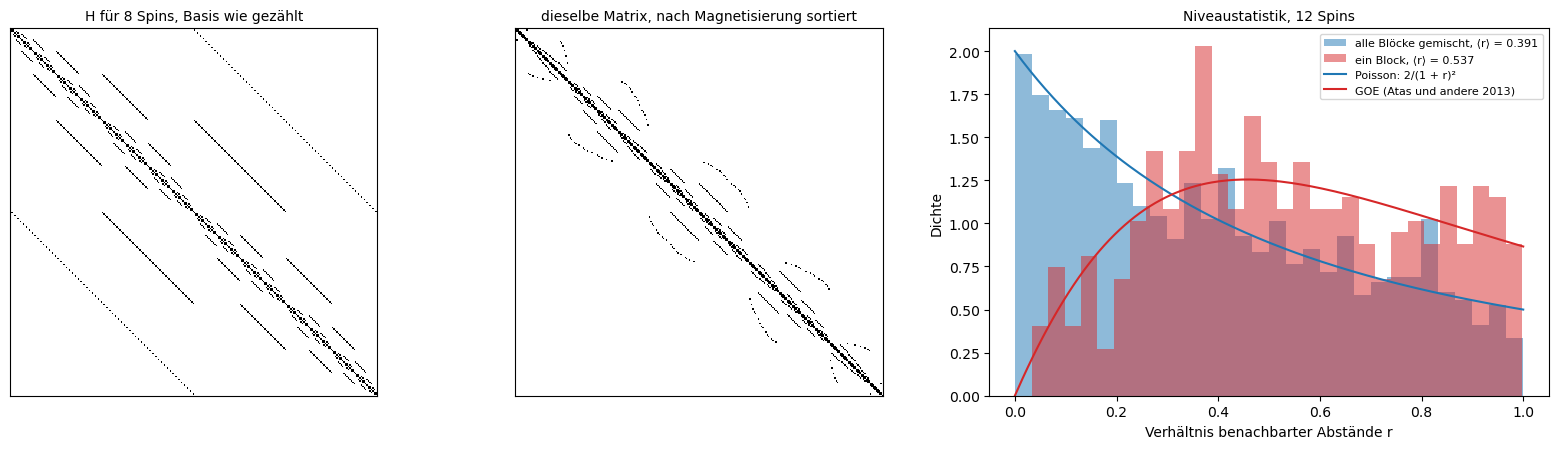

In [3]:
SPINS, DELTA, W = 12, 1.0, 1.0           # Zahl der Spins, Anisotropie Δ, Stärke der Zufallsfelder
symmetry.plot_sectors(SPINS, DELTA, W)

**3. Clifford-Symmetrie: Quantenschaltkreise, die ein Laptop simuliert**

Die Gatter H, S und CNOT haben eine besondere Eigenschaft: Sie machen aus jedem Pauli-String wieder einen Pauli-String, sie sind die Symmetrien der Pauli-Gruppe (die Clifford-Gruppe). Ein Zustand, der nur aus diesen Gattern entsteht, ist deshalb durch $n$ Pauli-Strings bestimmt, die ihn unverändert lassen, statt durch $2^n$ Amplituden; das ist der Satz von Gottesman und Knill. Ein Tableau-Simulator nach Aaronson und Gottesman (2004) speichert nur diese Strings (`stabilizer.plot_scaling`). Er wird an zufälligen Schaltkreisen gegen einen Zustandsvektor geprüft; dann wird ein GHZ-Zustand präpariert und gemessen, mit bis zu 1000 Qubits.

**Begriffe**
- **Stabilisator:** ein Pauli-String $g$ mit $g\vert\psi\rangle = \vert\psi\rangle$; der GHZ-Zustand aus 5 Qubits hat etwa XXXXX und ZZIII.
- **Tableau:** für 2n Pauli-Strings je ein Bit für X und eines für Z pro Qubit, dazu ein Vorzeichen.
- **Nicht-Clifford-Gatter:** etwa das T-Gatter, eine Drehung um π/4. Erst mit ihm wird die Simulation exponentiell schwer, und erst mit ihm kann ein Quantencomputer etwas, das klassisch unerreichbar ist.

Die Prüfung findet in 20 zufälligen Schaltkreisen keine Abweichung (4·10⁻¹⁷), der GHZ-Zustand hat die erwarteten Stabilisatoren, und alle Messungen ergeben dasselbe Bit. Der Zustandsvektor braucht bei 24 Qubits schon rund eine Sekunde und 256 MB, jedes weitere Qubit verdoppelt beides; bei 50 Qubits wären es 18 Petabyte. Das Tableau rechnet 1000 Qubits in einigen Sekunden und 0.5 MB, die Zeit wächst nur wie n². Die Symmetrie zieht hier eine Grenze in beide Richtungen: Sie macht diese Schaltkreise klassisch einfach, und sie zeigt damit, dass ein Quantenvorteil Gatter außerhalb der Clifford-Gruppe braucht, die sogenannte Magie. Das ist die Rechengrenze aus `limits_of_knowledge` von der anderen Seite.

Prüfung an 20 zufälligen Clifford-Schaltkreisen mit 8 Qubits: größte Abweichung von g|ψ⟩ = |ψ⟩ 3.9e-17
Stabilisatoren des GHZ-Zustands mit 5 Qubits: +XXXXX, +ZZIII, +IZZII, +IIZZI, +IIIZZ
Messung aller 5 Qubits: [0, 0, 0, 0, 0] (alle gleich, wie beim GHZ-Zustand)


Tableau:       10 Qubits 0.001 s, 30 Qubits 0.006 s, 100 Qubits 0.076 s, 300 Qubits 0.481 s, 1000 Qubits 6.201 s; wächst etwa wie n^1.9
Zustandsvektor: 10 Qubits 0.000 s, 14 Qubits 0.000 s, 18 Qubits 0.006 s, 20 Qubits 0.045 s, 22 Qubits 0.189 s, 24 Qubits 1.018 s; wächst etwa wie 2^(1.23·n)
Speicher: Zustandsvektor bei 50 Qubits 18 Petabyte, Tableau bei 1000 Qubits 0.5 Megabyte


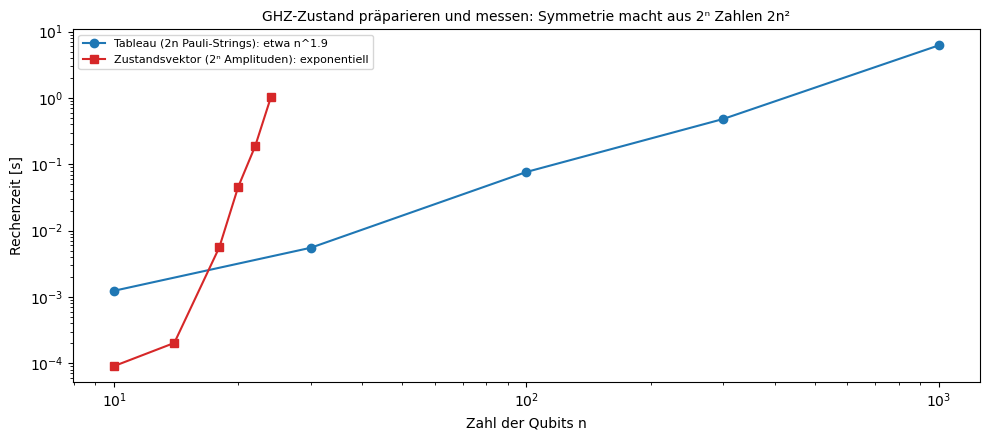

In [4]:
QUBITS_TABLEAU = (10, 30, 100, 300, 1000)      # Tableau: bis 1000 Qubits
QUBITS_VECTOR = (10, 14, 18, 20, 22, 24)        # Zustandsvektor: 24 Qubits sind schon 256 MB
stabilizer.plot_scaling(QUBITS_TABLEAU, QUBITS_VECTOR)

**4. Berry-Phase: Der Zustandsraum eines Qubits ist eine Kugel**

Jeder reine Zustand eines Qubits ist ein Punkt auf der Bloch-Kugel, in der Sprache der Geometrie die projektive Gerade $\mathbb{C}P^1$. Führt man ein Magnetfeld langsam einmal auf einem Kegel im Kreis, folgt der Spin dem Feld und kehrt am Ende in seinen Ausgangszustand zurück, bis auf eine Phase. Ein Teil davon ist dynamisch (Energie mal Zeit), der andere geometrisch: Er hängt nur von der umfahrenen Fläche ab, $\gamma = -\Omega/2$ mit dem Raumwinkel $\Omega = 2\pi(1 - \cos\theta)$ (Berry 1984). Simuliert wird der Umlauf für Öffnungswinkel von 0° bis 180° und drei Umlaufzeiten (`symmetry.plot_berry`).

**Begriffe**
- **Bloch-Kugel:** $\vert\psi\rangle = \cos(\theta/2)\vert 0\rangle + e^{i\varphi}\sin(\theta/2)\vert 1\rangle$ als Punkt mit Polarwinkel θ und Azimut φ.
- **Adiabatisch:** so langsam, dass der Spin dem Feld folgt; die Umlaufzeit muss groß sein gegen die Dauer einer Präzession (hier 2π).
- **Raumwinkel:** die Fläche, die der Weg auf der Einheitskugel umschließt; der ganze Himmel hat 4π.

Die numerischen Phasen liegen auf der Kurve des halben Raumwinkels: bei der Umlaufzeit 500 auf 0.02 rad genau, bei 100 auf 0.10 rad und bei 20 nur auf 0.48 rad, weil der Spin dem Feld dann nicht mehr ganz folgt (Überlapp mit dem Ausgangszustand 0.96). Sobald man langsam genug fährt, hängt die Phase also nicht von der Zeit ab, sondern nur von der Geometrie des Wegs auf der Kugel. Der Sprung bei 90° ist keiner: Phasen sind nur bis auf 2π bestimmt, −π und +π sind dasselbe. Das klassische Gegenstück ist das Foucault-Pendel, dessen Schwingungsebene sich an einem Tag um einen Winkel dreht, der von der umfahrenen Fläche auf der Erdkugel abhängt.

Umlaufzeit T =   20 (in 1/Feld): größte Abweichung von −Ω/2 0.4761 rad, Überlapp mit dem Startzustand mindestens 0.9637
Umlaufzeit T =  100 (in 1/Feld): größte Abweichung von −Ω/2 0.0989 rad, Überlapp mit dem Startzustand mindestens 0.9985
Umlaufzeit T =  500 (in 1/Feld): größte Abweichung von −Ω/2 0.0197 rad, Überlapp mit dem Startzustand mindestens 0.9999


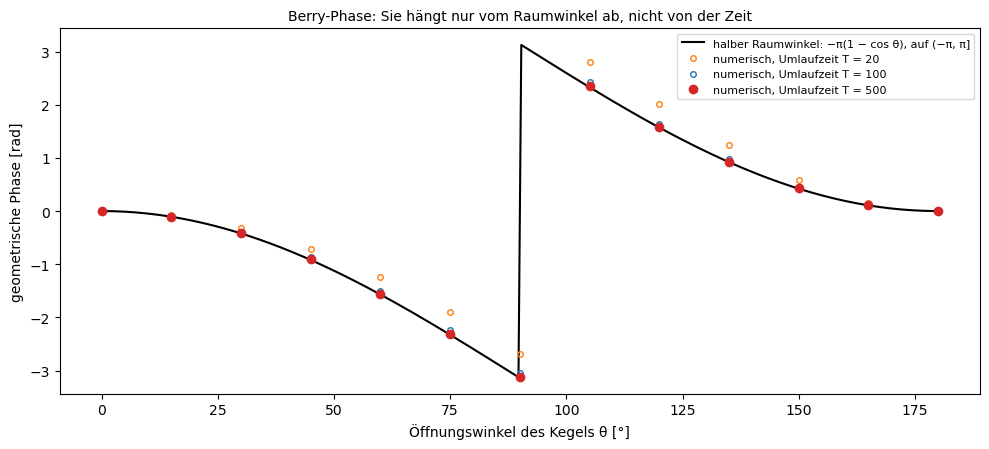

In [5]:
ANGLES = np.arange(0, 181, 15)          # Öffnungswinkel des Kegels [°]
TIMES = (20, 100, 500)                  # Umlaufzeiten in Einheiten von ħ/(Feldenergie)
symmetry.plot_berry(ANGLES, TIMES)

**5. Die verborgene Symmetrie der Kepler-Bahn und das Perihel des Merkur**

Ein Planet unter der Kraft 1/r² hat zwei Erhaltungsgrößen aus Symmetrien: den Drehimpuls (Drehsymmetrie, Noether) und den Laplace-Runge-Lenz-Vektor, der zum Perihel zeigt. Der zweite stammt aus einer verborgenen Symmetrie, die nur das 1/r²-Gesetz hat (die Gruppe SO(4)); sie ist der Grund, dass sich Kepler-Ellipsen schließen. Die allgemeine Relativitätstheorie fügt der Kraft in erster Ordnung einen kleinen Term mit 1/r⁴ hinzu und bricht damit diese Symmetrie, die Drehsymmetrie aber nicht. Integriert werden zehn Umläufe mit der Exzentrizität des Merkur, einmal nach Newton und einmal mit stark übertriebenem Zusatzterm (`orbits.plot_precession`); danach folgt die echte Zahl für den Merkur.

**Begriffe**
- **Laplace-Runge-Lenz-Vektor:** $\vec A = \vec v \times \vec L - \hat r$ (pro Masse, mit GM = 1); bei 1/r² ist er konstant und zeigt zum sonnennächsten Punkt.
- **Periheldrehung:** wie weit sich der sonnennächste Punkt je Umlauf weiterdreht; nach Einstein $6\pi GM/(c^2 a(1 - e^2))$.
- **Zusatzterm alpha:** Stärke des Terms $\alpha/r^2$ relativ zur Newton-Kraft; beim Merkur etwa $7\cdot10^{-8}$, hier 0.01, damit man ihn sieht.

Nach Newton ändert sich die Richtung des Runge-Lenz-Vektors in zehn Umläufen um 2·10⁻¹⁰ rad, also gar nicht: Die Ellipse schließt sich (links blau). Mit dem Zusatzterm wird die Bahn zur Rosette; der Drehimpuls bleibt erhalten (Änderung 10⁻¹¹), aber das Perihel wandert um 0.0704 rad je Umlauf (rechts). Die Formel erster Ordnung sagt 0.0685; die Abweichung schrumpft mit dem Zusatzterm (0.3 % bei einem Zehntel davon, 0.03 % bei einem Hundertstel), wie es für eine Näherung erster Ordnung sein muss. Für Merkur gibt die Formel 5.0·10⁻⁷ rad je Umlauf, bei 415 Umläufen im Jahrhundert 42.98″. Genau dieser Rest war übrig geblieben, nachdem man die Störungen durch die anderen Planeten abgezogen hatte, und er war 1915 der erste Erfolg der allgemeinen Relativitätstheorie: Die gebrochene Symmetrie ist hier die Messung.

Newton (1/r²), 10 Umläufe: Richtung des Runge-Lenz-Vektors ändert sich um 2.1e-10 rad, Betrag um 1.7e-11, Drehimpuls um 1.0e-11
Mit Zusatzterm alpha = 0.01: Perihel dreht sich je Umlauf um 0.07044 rad, Formel 2π·alpha/(1 − e²)² = 0.06850 rad; Drehimpuls bleibt erhalten (Änderung 1.3e-11)


  alpha = 0.001: 6.869e-03 rad je Umlauf, Formel 6.850e-03 (Verhältnis 1.0028)
  alpha = 0.0001: 6.852e-04 rad je Umlauf, Formel 6.850e-04 (Verhältnis 1.0003)
Merkur: 5.019e-07 rad je Umlauf, 415.2 Umläufe je Jahrhundert → 42.98″ pro Jahrhundert (beobachtet nach Abzug der anderen Planeten: etwa 43″)


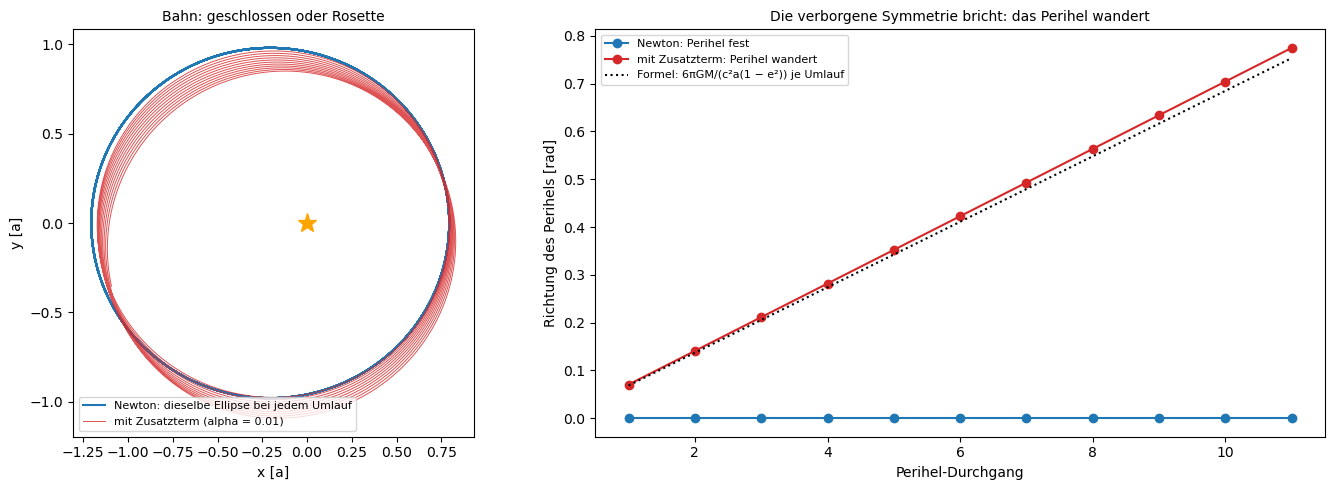

In [6]:
ECC, ALPHA, ORBITS = 0.2056, 0.01, 10    # Exzentrizität des Merkur, übertriebener Zusatzterm, Umläufe
orbits.plot_precession(ECC, ALPHA, ORBITS)

**6. Isotropie des Himmels: die kosmische Varianz**

Die Hintergrundstrahlung sieht in allen Richtungen statistisch gleich aus. Deshalb zerlegt man die Temperatur des Himmels in Kugelflächenfunktionen $Y_{\ell m}$, die Fourier-Moden der Kugel: Zu jedem Multipol ℓ gehören $2\ell + 1$ Koeffizienten $a_{\ell m}$, und Isotropie heißt, dass alle dieselbe Varianz $C_\ell$ haben. Mehr als diese $2\ell + 1$ Zahlen hat das eine beobachtbare Universum aber nicht; selbst ein perfektes Instrument schätzt $C_\ell$ deshalb nur auf $\sqrt{2/(2\ell+1)}$ genau, die kosmische Varianz. Verglichen wird das mit den Fehlern des Planck-Spektrums von 2018 (`cosmo.planck`, `cosmo.plot_cosmic_variance`).

**Begriffe**
- **Multipol ℓ:** Winkelskala etwa 180°/ℓ; ℓ = 2 ist der Quadrupol, die größten Flecken.
- $D_\ell = \ell(\ell+1)C_\ell/2\pi$: die übliche Darstellung des Spektrums, in µK².
- **Himmelsanteil:** Planck blendet die Milchstraße und helle Quellen aus und nutzt bei kleinen Winkeln je nach Frequenz etwa die Hälfte bis zwei Drittel des Himmels, hier gerechnet mit 60 %. Weniger Himmel heißt weniger unabhängige Werte und $1/\sqrt{0.6}$ größere Streuung.

Links liegen die Messwerte im Band der kosmischen Varianz um das beste Modell; bei großen Winkeln, links im Bild, ist das Band breit. Rechts liegt der Fehler von Planck von ℓ = 30 bis 500 nur 8 bis 11 % über der kosmischen Varianz für 60 % des Himmels, bei ℓ = 1000 rund 20 %; erst darüber dominieren Rauschen und Auflösung des Instruments (bei ℓ = 1500 schon 55 %). Bei großen Winkeln misst Planck also so genau, wie es das Universum überhaupt erlaubt; kein besseres Instrument käme dort weiter. Ein Beispiel ist der Quadrupol: gemessen 226 µK², das Modell sagt 1017 µK². Aus nur fünf Werten streut er so stark, dass ein so kleiner Wert in 4.7 % der möglichen Universen vorkommt, auffällig, aber kein Beweis für eine Abweichung. Die Symmetrie legt hier fest, wie viele unabhängige Messungen es überhaupt gibt, eine statistische Grenze wie in `limits_of_knowledge`.

  ℓ =   30:   61 Werte a_ℓm; relativer Fehler von Planck 0.260, kosmische Varianz 0.181 am ganzen Himmel, 0.234 bei 60% des Himmels
  ℓ =  100:  201 Werte a_ℓm; relativer Fehler von Planck 0.139, kosmische Varianz 0.100 am ganzen Himmel, 0.129 bei 60% des Himmels
  ℓ =  500: 1001 Werte a_ℓm; relativer Fehler von Planck 0.063, kosmische Varianz 0.045 am ganzen Himmel, 0.058 bei 60% des Himmels
  ℓ = 1000: 2001 Werte a_ℓm; relativer Fehler von Planck 0.050, kosmische Varianz 0.032 am ganzen Himmel, 0.041 bei 60% des Himmels
  ℓ = 1500: 3001 Werte a_ℓm; relativer Fehler von Planck 0.051, kosmische Varianz 0.026 am ganzen Himmel, 0.033 bei 60% des Himmels
  ℓ = 2000: 4001 Werte a_ℓm; relativer Fehler von Planck 0.159, kosmische Varianz 0.022 am ganzen Himmel, 0.029 bei 60% des Himmels
  Quadrupol ℓ = 2: gemessen 226 µK², Modell 1017 µK² (Verhältnis 0.22); aus nur 5 Werten streut er wie χ² mit 5 Freiheitsgraden, so klein oder kleiner in 4.7% der Fälle


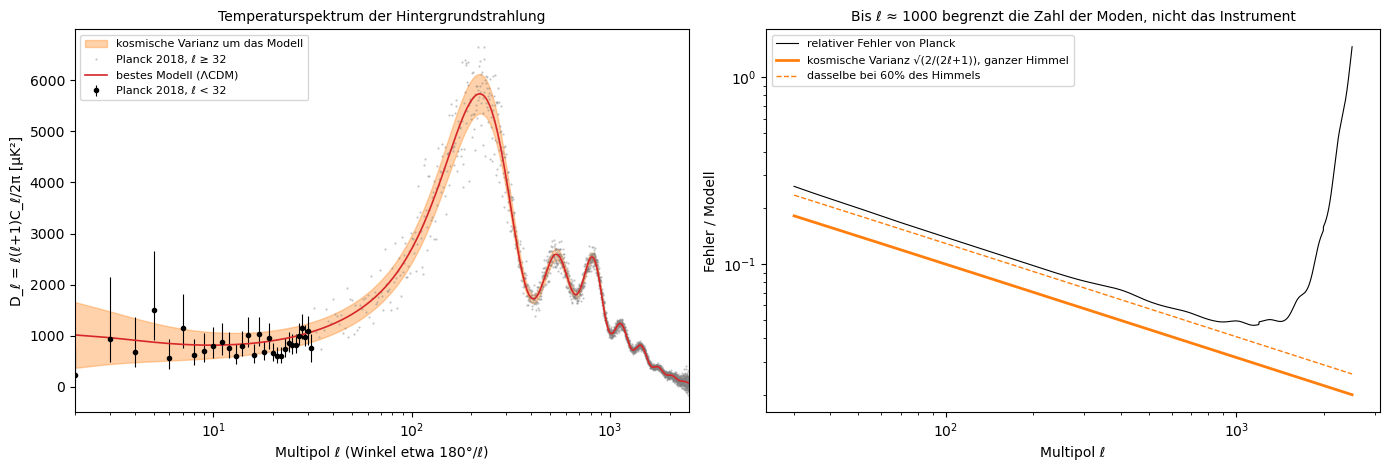

In [7]:
SKY_FRACTION = 0.6                      # genutzter Anteil des Himmels bei kleinen Winkeln
spectrum, model = cosmo.planck(DATA / "planck")  # 2 Dateien, zusammen 0.4 MB
cosmo.plot_cosmic_variance(spectrum, model, SKY_FRACTION)

**7. Alcock-Paczynski: Isotropie misst die Materiedichte**

Schallwellen im frühen Universum (Baryonische Akustische Oszillationen, BAO) haben in der Verteilung der Galaxien einen bevorzugten Abstand von etwa 150 Mpc hinterlassen; in einem isotropen Universum ist diese Struktur im Mittel kugelrund. Gemessen wird sie aber in zwei Richtungen verschieden: quer zur Sichtlinie über Winkel ($D_M$, die mitbewegte Entfernung) und längs über Rotverschiebungen ($D_H = c/H$). Rechnet man mit der falschen Kosmologie um, wird die Kugel zum Ellipsoid. Das Verhältnis $F_{AP} = D_M/D_H$ hängt deshalb nur von der Form der Expansionsgeschichte ab, nicht von H₀ und nicht von der Größe des Lineals (Alcock und Paczynski 1979). Aus den Daten von DESI (Data Release 2, 2025) wird $F_{AP}$ bei sechs Rotverschiebungen gebildet und Ω_m im flachen ΛCDM-Modell angepasst (`cosmo.desi`, `cosmo.plot_ap`).

**Begriffe**
- $D_M$ **und** $D_H$: die Entfernung quer zur Sichtlinie (aus dem Winkel) und längs (aus der Rotverschiebung), beide in Einheiten des Lineals $r_d$; im Verhältnis fällt $r_d$ heraus.
- **Ω_m:** der Anteil der Materie an der Energiedichte heute; den Rest trägt im flachen ΛCDM-Modell die Dunkle Energie.
- **χ²:** mit der vollen Kovarianz der DESI-Messungen, wie in Schritt 8 von `principal_axes`.

Die sechs Punkte folgen der Kurve für Ω_m = 0.299 (± 0.017), mit χ² = 5.9 bei 5 Freiheitsgraden; die Kurven für 0.2 und 0.4 liegen deutlich daneben (links). Planck findet aus der Hintergrundstrahlung 0.315 ± 0.007, knapp 1σ entfernt. Bemerkenswert ist, was hier nicht eingeht: weder H₀ noch die Größe des Lineals noch eine Helligkeit, sondern nur die Annahme, dass das Universum keine Richtung bevorzugt. Die Symmetrie ist hier selbst das Messinstrument.

DESI DR2: 6 Rotverschiebungen mit D_M und D_H, z = 0.51, 0.71, 0.93, 1.32, 1.48, 2.33
  Ω_m aus F_AP allein: 0.299 (−0.017, +0.017), χ² = 5.9 bei 5 Freiheitsgraden; zum Vergleich Planck 2018: 0.315 ± 0.007


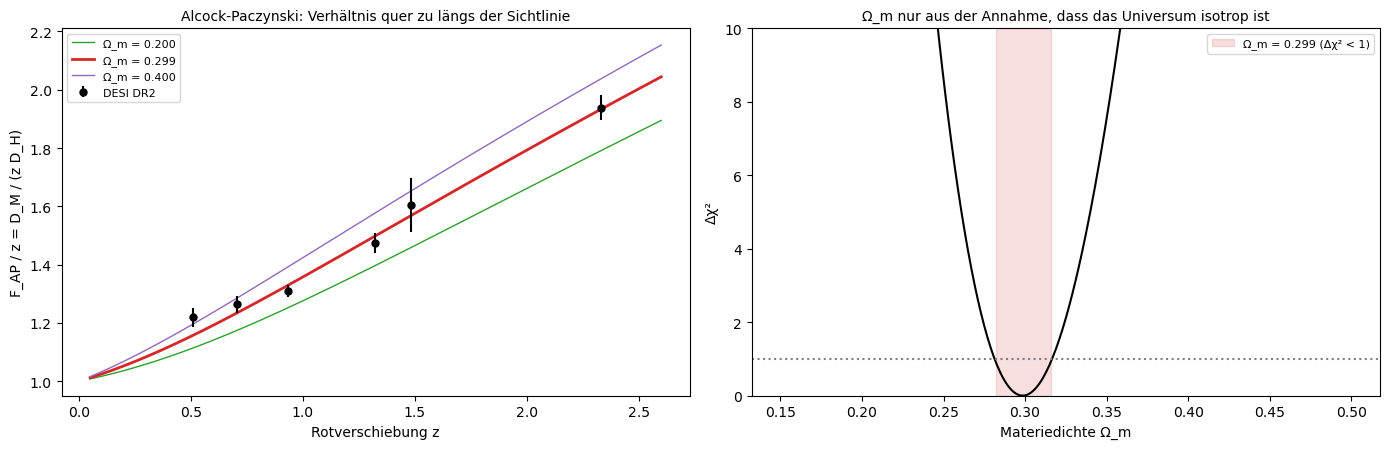

In [8]:
bao, bao_cov = cosmo.desi(DATA / "desi")          # 2 kleine Dateien
z_ap, f_ap, f_ap_cov = cosmo.ap_data(bao, bao_cov)
omega_m = cosmo.plot_ap(z_ap, f_ap, f_ap_cov)